In [1]:
# Importing the required libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the unemployment dataset from the CSV file

df = pd.read_csv("data/Unemployment in India.csv")

In [3]:
# Displaying the first five rows to understand the dataset structure

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [4]:
# Checking the number of rows and columns in the dataset

print("Dataset Shape:", df.shape)

Dataset Shape: (768, 7)


In [5]:
# Displaying column names, data types, non-null values and memory usage

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB


In [6]:
# Generating a statistical summary of numerical columns in the dataset

df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [7]:
# Checking the number of missing values in each column

df.isnull().sum()

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

In [8]:
# Checking the number of rows where all columns contain missing values

df.isnull().all(axis=1).sum()

np.int64(28)

In [9]:
# Removing completely empty rows from the dataset

df = df.dropna(how='all')

# Checking the updated dataset dimensions

print("Updated Dataset Shape:", df.shape)

Updated Dataset Shape: (740, 7)


In [10]:
# Checking the number of duplicate rows in the dataset

df.duplicated().sum()

np.int64(0)

In [11]:
# Removing leading and trailing spaces from column names

df.columns = df.columns.str.strip()

# Displaying the updated column names

df.columns

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='str')

In [12]:
# Converting the Date column from string to datetime format

df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Checking the updated data type

print(df['Date'].dtype)

datetime64[us]


In [13]:
# Checking missing values after removing empty rows

df.isnull().sum()

Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

In [14]:
# Displaying the updated dataset information after cleaning

df.info()

<class 'pandas.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    str           
 1   Date                                     740 non-null    datetime64[us]
 2   Frequency                                740 non-null    str           
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    str           
dtypes: datetime64[us](1), float64(3), str(3)
memory usage: 46.2 KB


In [15]:
# Displaying all unique regions in the dataset

df['Region'].unique()

<StringArray>
[  'Andhra Pradesh',            'Assam',            'Bihar',
     'Chhattisgarh',            'Delhi',              'Goa',
          'Gujarat',          'Haryana', 'Himachal Pradesh',
  'Jammu & Kashmir',        'Jharkhand',        'Karnataka',
           'Kerala',   'Madhya Pradesh',      'Maharashtra',
        'Meghalaya',           'Odisha',       'Puducherry',
           'Punjab',        'Rajasthan',           'Sikkim',
       'Tamil Nadu',        'Telangana',          'Tripura',
    'Uttar Pradesh',      'Uttarakhand',      'West Bengal',
       'Chandigarh']
Length: 28, dtype: str

In [16]:
# Checking the minimum and maximum dates in the dataset

print("Start Date:", df['Date'].min())
print("End Date:", df['Date'].max())

Start Date: 2019-05-31 00:00:00
End Date: 2020-06-30 00:00:00


In [17]:
# Checking the unique data collection frequencies

df['Frequency'].unique()

<StringArray>
[' Monthly', 'Monthly']
Length: 2, dtype: str

In [18]:
# Removing extra spaces from Frequency values

df['Frequency'] = df['Frequency'].str.strip()

# Checking the updated unique values

df['Frequency'].unique()

<StringArray>
['Monthly']
Length: 1, dtype: str

In [19]:
# Checking the unique area categories in the dataset

df['Area'].unique()

<StringArray>
['Rural', 'Urban']
Length: 2, dtype: str

In [20]:
# Calculating overall unemployment rate statistics

print("Average Unemployment Rate:", df['Estimated Unemployment Rate (%)'].mean())
print("Maximum Unemployment Rate:", df['Estimated Unemployment Rate (%)'].max())
print("Minimum Unemployment Rate:", df['Estimated Unemployment Rate (%)'].min())

Average Unemployment Rate: 11.787945945945946
Maximum Unemployment Rate: 76.74
Minimum Unemployment Rate: 0.0


In [21]:
# Calculating the average unemployment rate for each region

region_avg = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().sort_values(ascending=False)

# Displaying the average unemployment rate region-wise

region_avg

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64

### Observation: Region-wise Average Unemployment

- Tripura recorded the highest average unemployment rate at 28.35%.
- Haryana ranked second with 26.28%.
- Meghalaya recorded the lowest average unemployment rate at 4.80%.
- Tamil Nadu recorded an average unemployment rate of 9.28%.

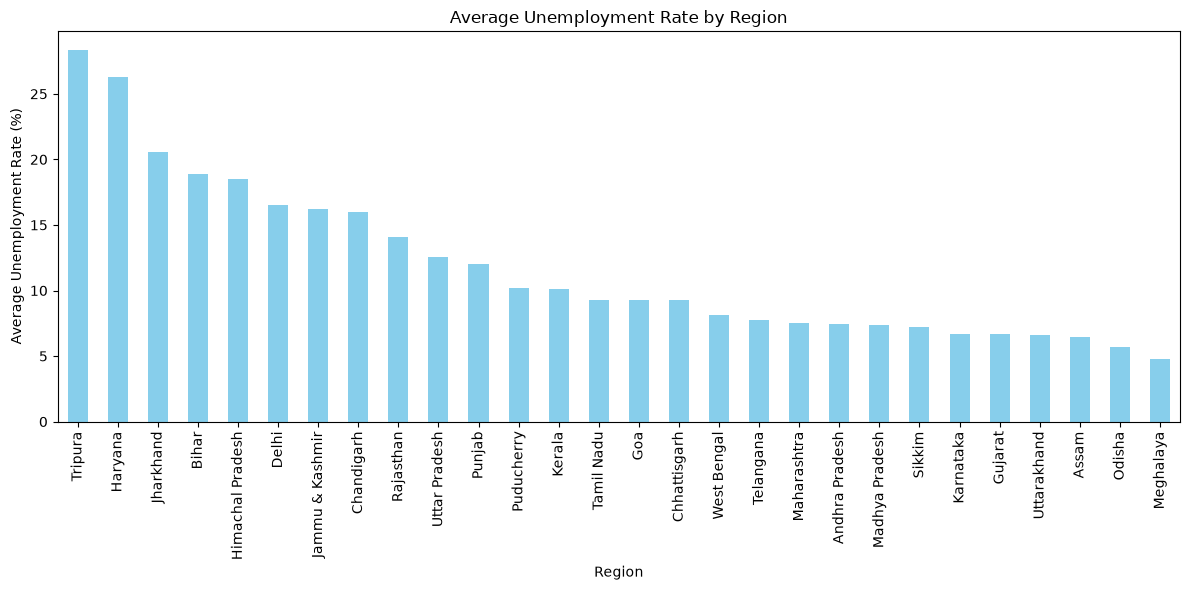

In [22]:
# Plotting average unemployment rate across all regions

plt.figure(figsize=(12, 6))

region_avg.plot(kind='bar', color='skyblue')

plt.title('Average Unemployment Rate by Region')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

### Observation: Average Unemployment Rate by Region

- Tripura recorded the highest average unemployment rate.
- Haryana and Jharkhand also showed relatively high unemployment rates.
- Meghalaya recorded the lowest average unemployment rate.
- There is considerable variation in unemployment rates across different regions.

In [23]:
# Calculating the average unemployment rate for each month

monthly_avg = df.groupby('Date')['Estimated Unemployment Rate (%)'].mean()

# Displaying monthly average unemployment rates

monthly_avg

Date
2019-05-31     8.874259
2019-06-30     9.303333
2019-07-31     9.033889
2019-08-31     9.637925
2019-09-30     9.051731
2019-10-31     9.900909
2019-11-30     9.868364
2019-12-31     9.497358
2020-01-31     9.950755
2020-02-29     9.964717
2020-03-31    10.700577
2020-04-30    23.641569
2020-05-31    24.875294
2020-06-30    11.903600
Name: Estimated Unemployment Rate (%), dtype: float64

### Observation: Monthly Unemployment Trend

- Unemployment remained relatively stable between May 2019 and February 2020.
- A noticeable increase occurred in March 2020.
- April and May 2020 recorded sharp increases in unemployment.
- May 2020 had the highest average unemployment rate of 24.88%.
- Unemployment declined considerably in June 2020.

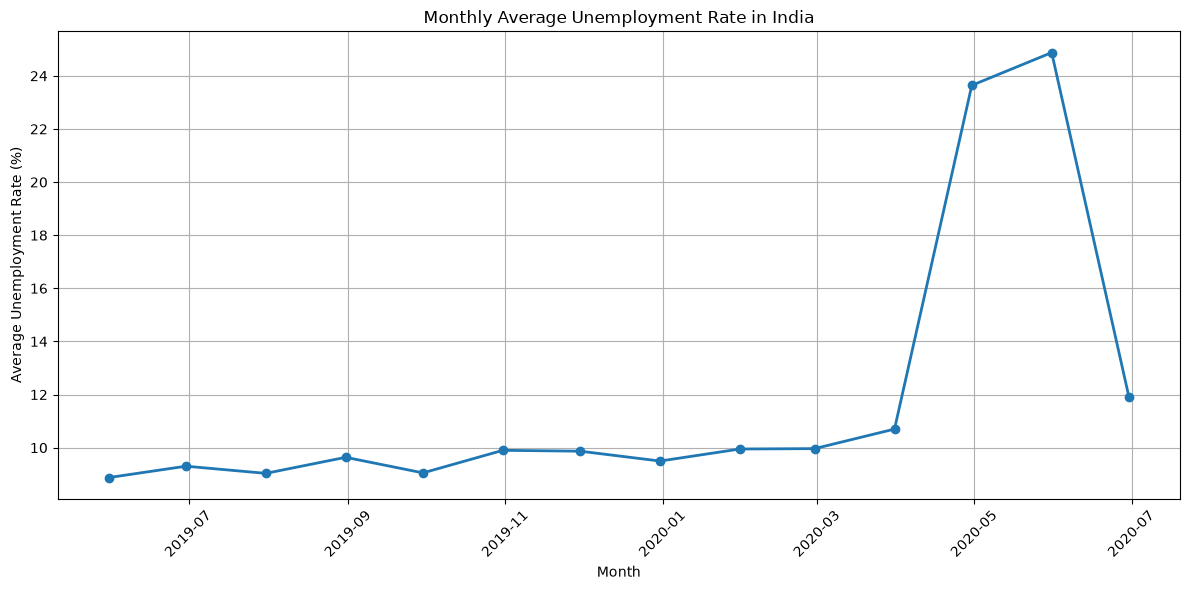

In [24]:
# Plotting the monthly average unemployment rate

plt.figure(figsize=(12, 6))

plt.plot(monthly_avg.index, monthly_avg.values, marker='o', linewidth=2)

plt.title('Monthly Average Unemployment Rate in India')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [25]:
# Filtering unemployment data for three selected states

selected_states = ['Tamil Nadu', 'Kerala', 'Haryana']

state_data = df[df['Region'].isin(selected_states)]

# Calculating monthly average unemployment for each selected state

state_monthly = state_data.groupby(['Date', 'Region'])['Estimated Unemployment Rate (%)'].mean().unstack()

# Displaying the results

state_monthly

Region,Haryana,Kerala,Tamil Nadu
Date,,,
2019-05-31,19.605,6.370,0.930
2019-06-30,21.750,7.835,1.240
2019-07-31,20.835,6.265,4.595
2019-08-31,27.565,9.005,6.220
2019-09-30,21.600,5.435,1.785
2019-10-31,22.605,7.245,1.295
2019-11-30,21.825,5.855,2.555
2019-12-31,26.605,9.040,5.890
2020-01-31,21.725,5.380,1.615


### Observation: State-wise Unemployment Trends

- Haryana maintained relatively high unemployment rates throughout the observed period.
- Tamil Nadu recorded its highest unemployment rate of 49.37% in April 2020.
- Kerala recorded its highest unemployment rate of 26.83% in May 2020.
- All three states experienced a noticeable increase in unemployment during the COVID-19 period.

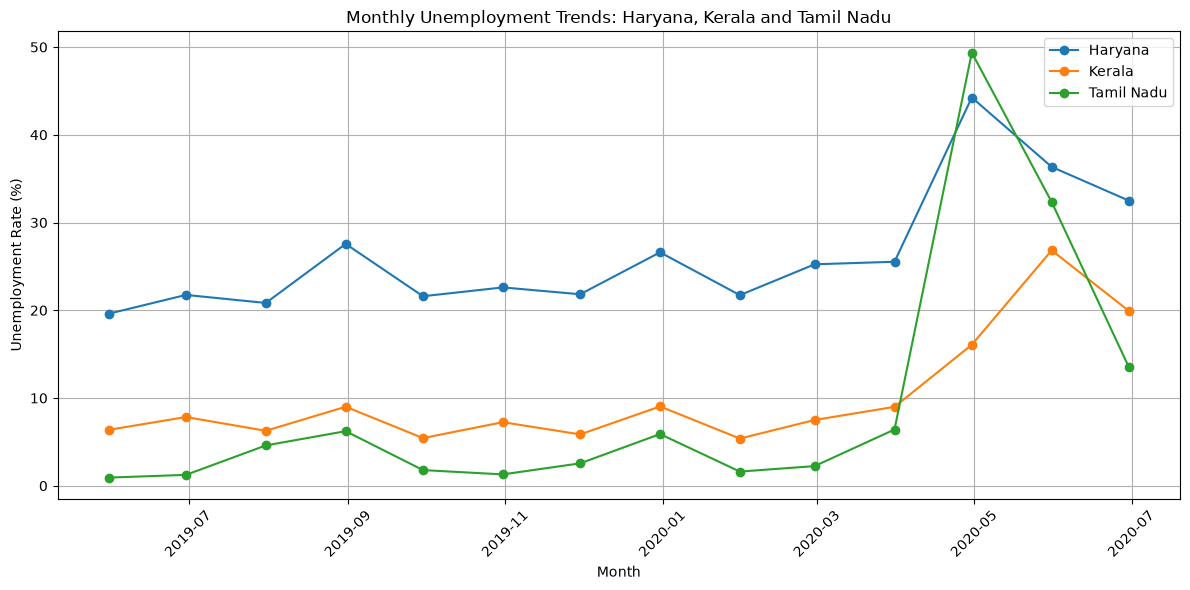

In [26]:
# Plotting monthly unemployment trends for three selected states

plt.figure(figsize=(12, 6))

for state in state_monthly.columns:
    plt.plot(state_monthly.index, state_monthly[state], marker='o', label=state)

plt.title('Monthly Unemployment Trends: Haryana, Kerala and Tamil Nadu')
plt.xlabel('Month')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

### Observation: State-wise Unemployment Trends

- Haryana recorded relatively high unemployment rates throughout 2019.
- Tamil Nadu experienced the highest unemployment rate among the selected states, reaching 49.37% in April 2020.
- Haryana reached 44.25% in April 2020.
- Kerala recorded its highest rate of 26.83% in May 2020.
- All three states experienced sharp increases during the COVID-19 period.

In [27]:
# Selecting the top 10 regions with the highest average unemployment rates

top_10_regions = region_avg.head(10)

# Displaying the top 10 regions

top_10_regions

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64

### Observation: Top 10 Regions with Highest Unemployment

- Tripura recorded the highest average unemployment rate at 28.35%.
- Haryana ranked second with 26.28%.
- Jharkhand ranked third with 20.59%.
- Uttar Pradesh ranked tenth with 12.55%.
- These regions experienced comparatively higher unemployment rates during the study period.

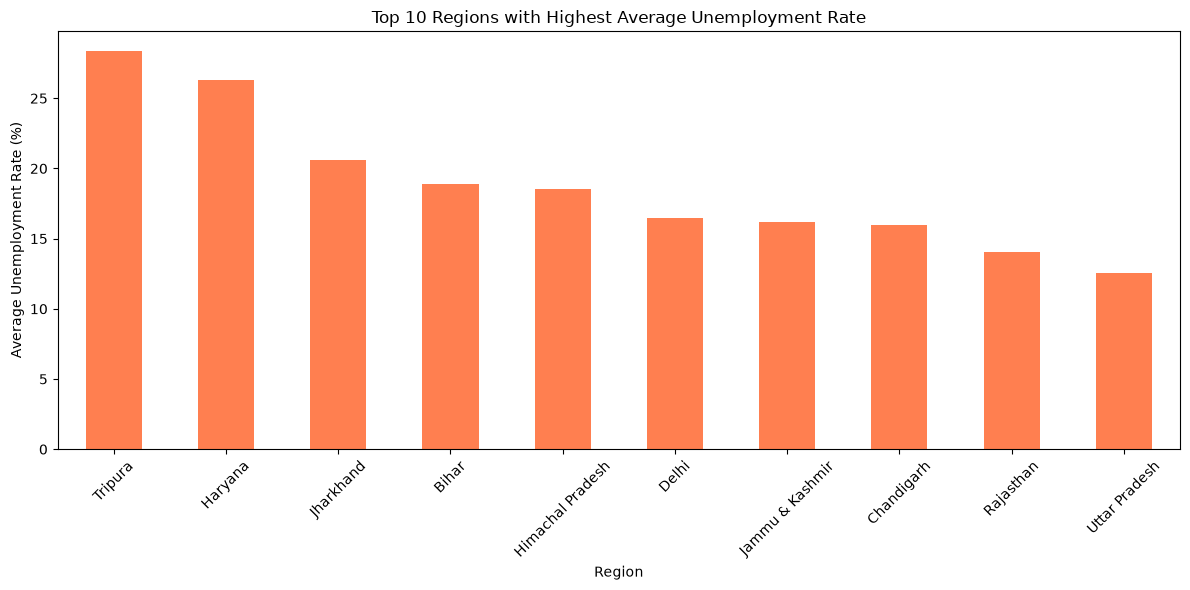

In [28]:
# Visualizing the top 10 regions with the highest average unemployment rates

plt.figure(figsize=(12, 6))

top_10_regions.plot(kind='bar', color='coral')

plt.title('Top 10 Regions with Highest Average Unemployment Rate')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [29]:
# Calculating the estimated employment rate

df['Estimated Employment Rate (%)'] = (
    df['Estimated Labour Participation Rate (%)'] *
    (1 - df['Estimated Unemployment Rate (%)'] / 100)
)

# Displaying the three unemployment indicators

df[['Estimated Unemployment Rate (%)',
    'Estimated Employment Rate (%)',
    'Estimated Labour Participation Rate (%)']].head()

,Estimated Unemployment Rate (%),Estimated Employment Rate (%),Estimated Labour Participation Rate (%)
0,3.65,41.661740,43.24
1,3.05,40.767475,42.05
2,3.75,41.868750,43.50
3,3.32,42.510196,43.97
4,5.17,42.370044,44.68


### Estimated Employment Rate

The estimated employment rate is derived using the unemployment rate and labour participation rate. It represents the estimated percentage of the working-age population that is employed.

In [30]:
# Calculating correlation between the three unemployment indicators

correlation = df[
    ['Estimated Unemployment Rate (%)',
     'Estimated Employment Rate (%)',
     'Estimated Labour Participation Rate (%)']
].corr()

# Displaying the correlation matrix

correlation

,Estimated Unemployment Rate (%),Estimated Employment Rate (%),Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.541232,0.002558
Estimated Employment Rate (%),-0.541232,1.000000,0.829870
Estimated Labour Participation Rate (%),0.002558,0.829870,1.000000


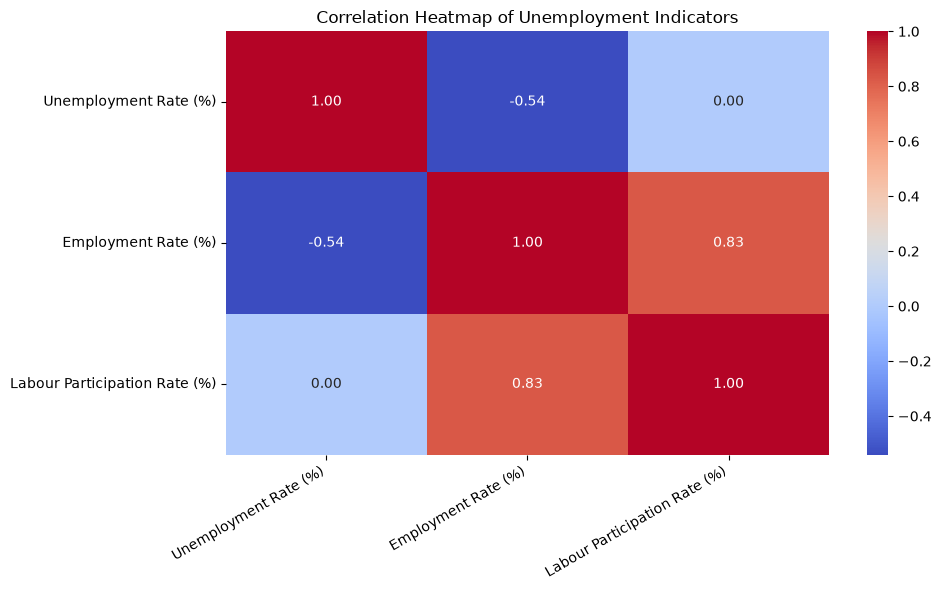

In [31]:
# Creating the correlation heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    xticklabels=['Unemployment Rate (%)',
                 'Employment Rate (%)',
                 'Labour Participation Rate (%)'],
    yticklabels=['Unemployment Rate (%)',
                 'Employment Rate (%)',
                 'Labour Participation Rate (%)']
)

plt.title('Correlation Heatmap of Unemployment Indicators')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

### Observation: Correlation Between Unemployment Indicators

- Unemployment Rate and Employment Rate showed a moderate negative correlation of -0.54.
- Employment Rate and Labour Participation Rate showed a strong positive correlation of 0.83.
- Unemployment Rate and Labour Participation Rate showed almost no linear correlation.
- The employment rate is a derived indicator calculated using the other two rates.

In [32]:
# Separating the dataset into pre-COVID and COVID periods

pre_covid = df[df['Date'] < '2020-03-01']

covid_period = df[df['Date'] >= '2020-03-01']

# Checking the number of records in each period

print("Pre-COVID Records:", pre_covid.shape[0])
print("COVID Period Records:", covid_period.shape[0])

Pre-COVID Records: 536
COVID Period Records: 204


In [33]:
# Calculating average unemployment rates before and during COVID-19

pre_covid_avg = pre_covid['Estimated Unemployment Rate (%)'].mean()

covid_avg = covid_period['Estimated Unemployment Rate (%)'].mean()

# Displaying the comparison

print("Pre-COVID Average Unemployment Rate:", round(pre_covid_avg, 2), "%")
print("COVID Period Average Unemployment Rate:", round(covid_avg, 2), "%")

Pre-COVID Average Unemployment Rate: 9.51 %
COVID Period Average Unemployment Rate: 17.77 %


In [34]:
# Calculating the percentage increase in unemployment during COVID-19

percentage_increase = ((covid_avg - pre_covid_avg) / pre_covid_avg) * 100

print("Percentage Increase in Unemployment:", round(percentage_increase, 2), "%")

Percentage Increase in Unemployment: 86.91 %


### Observation: Pre-COVID vs COVID-period Comparison

- The average unemployment rate before COVID-19 was 9.51%.
- During the COVID period, it increased to 17.77%.
- This represents an increase of 8.26 percentage points.
- The percentage increase in unemployment was approximately 86.91%.
- The comparison highlights a substantial rise in unemployment during the COVID-19 period.

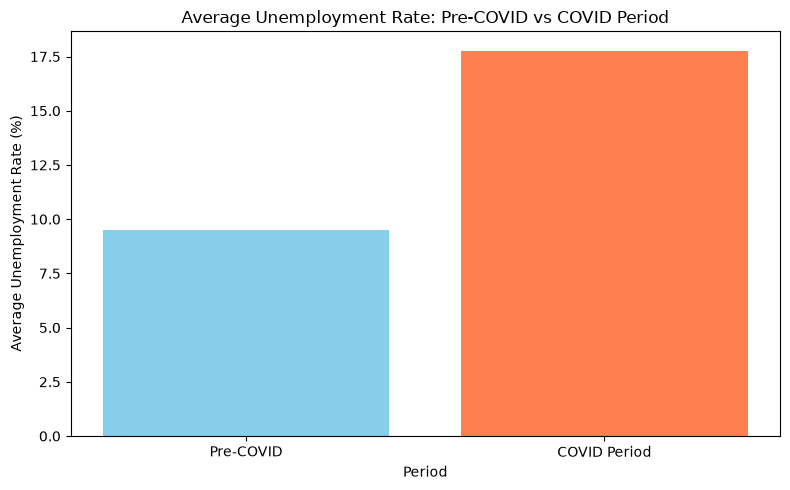

In [35]:
# Comparing average unemployment rates before and during COVID-19

plt.figure(figsize=(8, 5))

periods = ['Pre-COVID', 'COVID Period']
rates = [pre_covid_avg, covid_avg]

plt.bar(periods, rates, color=['skyblue', 'coral'])

plt.title('Average Unemployment Rate: Pre-COVID vs COVID Period')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')

plt.tight_layout()
plt.show()

In [36]:
# Calculating average unemployment rates for Rural and Urban areas

area_avg = df.groupby('Area')['Estimated Unemployment Rate (%)'].mean()

# Displaying the results

area_avg

Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64

### Observation: Rural vs Urban Unemployment

- Urban areas recorded a higher average unemployment rate of 13.17%.
- Rural areas recorded an average unemployment rate of 10.32%.
- The results indicate higher unemployment in urban areas during the study period.

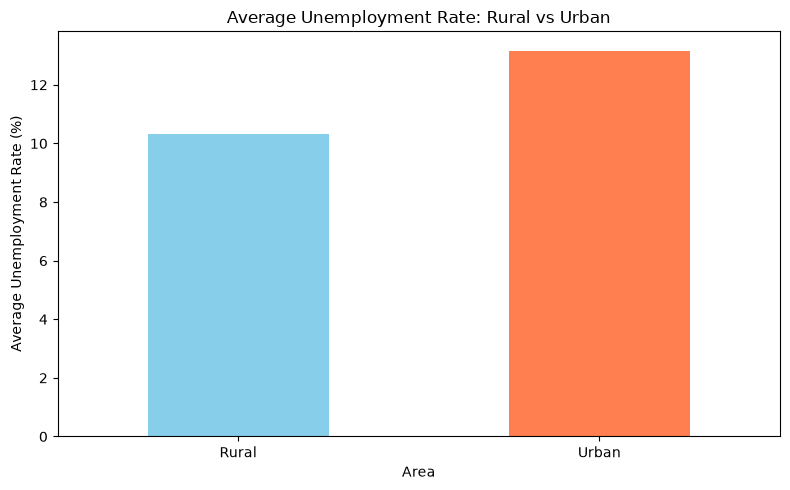

In [37]:
# Comparing average unemployment rates in Rural and Urban areas

plt.figure(figsize=(8, 5))

area_avg.plot(kind='bar', color=['skyblue', 'coral'])

plt.title('Average Unemployment Rate: Rural vs Urban')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## Conclusion

This Exploratory Data Analysis (EDA) provided insights into unemployment trends across different regions of India from May 2019 to June 2020.

The key findings are:

- Tripura recorded the highest average unemployment rate (28.35%), followed by Haryana (26.28%).
- The monthly trend showed a sharp increase in unemployment during April and May 2020.
- The average unemployment rate increased from 9.51% before COVID-19 to 17.77% during the COVID period, representing an increase of approximately 86.91%.
- Urban areas recorded a higher average unemployment rate (13.17%) compared to rural areas (10.32%).
- Correlation analysis revealed a moderate negative relationship between unemployment rate and the derived employment rate.

Overall, the analysis highlights significant regional variations and a substantial rise in unemployment during the COVID-19 period. This project demonstrates how Python, Pandas, Matplotlib and Seaborn can be used to explore datasets, identify patterns and derive meaningful insights from real-world data.